# Results summary: all models, all metrics, all three settings (validation)

This notebook **trains nothing**. It collects the saved results of notebooks 02–09 into one place.

| Setting | Known when deciding | PD notebook | Rate notebook |
|---|---|---|---|
| **Reference:** already-priced loan | rate + grade | 02–05 | none (rate already set) |
| **Pipeline A:** graded applicant | grade only | 08 | 09 |
| **Pipeline B:** newcomer | neither | 06 | 07 |

**All numbers are validation scores**: 5-fold cross-validation on the 80% training set, using out-of-fold predictions (each applicant scored by a model that did not train on them). The 20% test set has **not** been used yet; the final test results get their own notebook with the same layout.

**Metric guide**

| Metric | Meaning | Better |
|---|---|---|
| Precision | of applicants flagged as defaulters, the share who really defaulted | higher |
| Recall | of real defaulters, the share we flagged | higher |
| **F1** | balance of precision and recall (main classification metric) | higher |
| Accuracy | share of all predictions that are right (misleading here: "everyone repays" scores 0.781) | higher |
| ROC-AUC | how well the model ranks risky above safe applicants, at any cutoff (0.5 = random) | higher |
| **Brier score** | mean of (PD − outcome)²: accuracy of the probability of default (always guessing 0.219 gives 0.171) | lower |
| Log loss | like Brier, but punishes confident mistakes heavily (always guessing 0.219 gives 0.526) | lower |
| ECE | average gap between predicted PD and the actual default rate, over 10 equal-size groups | lower |
| Mean PD | should equal the real default rate (0.219) | ≈ 0.219 |
| **RMSE** | typical error of the predicted interest rate, in percentage points (pp) | lower |
| MAE | average absolute error of the predicted rate, in pp | lower |
| **R²** | share of the variation in interest rates explained (0 = guessing the average rate) | higher |

Precision, recall, F1 and accuracy are measured at **each model's own tuned cutoff**; Brier, log loss, ECE and mean PD use **each model's best calibrated PD**.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.credit import DATA, REPORTS, load_train, make_cv, best_cutoff, fold_metrics

pd.set_option("display.max_colwidth", 90)
X_train, y_train = load_train()
cv = make_cv()

SETTINGS = [("Reference (rate + grade)", "oof_scores.npz", "pd_summary.csv"),
            ("Pipeline A (grade)", "oof_scores_graded.npz", "graded_pd_summary.csv"),
            ("Pipeline B (newcomer)", "oof_scores_applicant.npz", "applicant_pd_summary.csv")]

def family(name):
    # short model label shared by all three settings
    for key in ["Random Forest", "Tree", "SVM RBF + SMOTE", "SVM RBF", "Linear SVM + SMOTE", "Linear SVM",
                "LogReg + SMOTE", "LogReg"]:
        if name.startswith(key):
            return key.replace("SVM RBF", "RBF SVM") if "SMOTE" in key else key.replace("SVM RBF", "RBF SVM")
    return name

rows = []
for setting, cache, summary_file in SETTINGS:
    oof = dict(np.load(DATA / cache))
    summary = pd.read_csv(REPORTS / summary_file, index_col=0)
    for name in summary.index:
        s = oof[name]
        fm = fold_metrics(s, y_train, best_cutoff(s, y_train), X_train, cv)
        rows.append({"setting": setting, "model": family(name), "settings used": name,
                     "precision": fm.loc["mean", "precision"], "recall": fm.loc["mean", "recall"],
                     "F1": fm.loc["mean", "f1"], "F1 sd": fm.loc["sd", "f1"], "accuracy": fm.loc["mean", "accuracy"],
                     "ROC-AUC": fm.loc["mean", "roc_auc"], "PD calibration": summary.loc[name, "PD method"],
                     "Brier": summary.loc[name, "Brier"], "log loss": summary.loc[name, "log loss"],
                     "ECE": summary.loc[name, "ECE"], "mean PD": summary.loc[name, "mean PD"]})
clf = pd.DataFrame(rows)
clf.to_csv(REPORTS / "all_classification_scores.csv", index=False)
print(f"{len(clf)} model results collected ({clf['model'].nunique()} models x {clf['setting'].nunique()} settings); "
      f"saved reports/all_classification_scores.csv")

24 model results collected (8 models x 3 settings); saved reports/all_classification_scores.csv


## 1. Predicting default: every model, every metric, per setting

In [2]:
METRICS = ["precision", "recall", "F1", "F1 sd", "accuracy", "ROC-AUC", "Brier", "log loss", "ECE", "mean PD",
           "PD calibration"]
for setting, g in clf.groupby("setting", sort=False):
    print(f"\n{setting}  (sorted by F1)")
    display(g.set_index("model")[METRICS].sort_values("F1", ascending=False).round(4))


Reference (rate + grade)  (sorted by F1)


,precision,recall,F1,F1 sd,accuracy,ROC-AUC,Brier,log loss,ECE,mean PD,PD calibration
model,,,,,,,,,,,
Random Forest,0.9553,0.7335,0.8298,0.0043,0.9342,0.9342,0.0556,0.2019,0.0017,0.2186,isotonic
Tree,0.9707,0.6991,0.8128,0.0033,0.9296,0.9062,0.0619,0.2312,0.0026,0.2192,isotonic
RBF SVM,0.9084,0.6905,0.7845,0.0069,0.9170,0.9058,0.0690,0.2488,0.0029,0.2188,isotonic
RBF SVM + SMOTE,0.8683,0.6963,0.7728,0.0097,0.9104,0.9080,0.0730,0.2584,0.0021,0.2186,isotonic
Linear SVM,0.6882,0.6783,0.6831,0.0032,0.8624,0.8658,0.1014,0.3389,0.0026,0.2187,isotonic
Linear SVM + SMOTE,0.6682,0.6919,0.6797,0.0062,0.8574,0.8669,0.1034,0.3428,0.0045,0.2187,isotonic
LogReg,0.6803,0.6739,0.6770,0.0050,0.8593,0.8689,0.1015,0.3381,0.0035,0.2187,isotonic
LogReg + SMOTE,0.6789,0.6718,0.6752,0.0059,0.8586,0.8698,0.1028,0.3407,0.0029,0.2187,isotonic



Pipeline A (grade)  (sorted by F1)


,precision,recall,F1,F1 sd,accuracy,ROC-AUC,Brier,log loss,ECE,mean PD,PD calibration
model,,,,,,,,,,,
Random Forest,0.9510,0.7316,0.8269,0.0046,0.9330,0.9336,0.0564,0.2038,0.0028,0.2186,isotonic
Tree,0.9603,0.7072,0.8145,0.0041,0.9296,0.9090,0.0606,0.2262,0.0031,0.2193,isotonic
RBF SVM,0.9008,0.6942,0.7840,0.0092,0.9163,0.9056,0.0692,0.2485,0.0020,0.2187,isotonic
RBF SVM + SMOTE,0.8705,0.6937,0.7720,0.0107,0.9104,0.9073,0.0727,0.2579,0.0039,0.2186,isotonic
Linear SVM,0.6767,0.6901,0.6833,0.0045,0.8601,0.8654,0.1014,0.3391,0.0030,0.2187,isotonic
Linear SVM + SMOTE,0.6731,0.6885,0.6807,0.0076,0.8587,0.8661,0.1036,0.3438,0.0031,0.2187,isotonic
LogReg,0.6760,0.6801,0.6779,0.0038,0.8587,0.8685,0.1015,0.3383,0.0028,0.2186,isotonic
LogReg + SMOTE,0.6664,0.6841,0.6750,0.0057,0.8559,0.8693,0.1028,0.3407,0.0026,0.2187,isotonic



Pipeline B (newcomer)  (sorted by F1)


,precision,recall,F1,F1 sd,accuracy,ROC-AUC,Brier,log loss,ECE,mean PD,PD calibration
model,,,,,,,,,,,
Random Forest,0.8094,0.6032,0.6912,0.0070,0.8821,0.8824,0.0879,0.2959,0.0077,0.2187,Platt (sigmoid)
Tree,0.8359,0.5540,0.6661,0.0058,0.8785,0.8514,0.0939,0.3174,0.0051,0.2191,isotonic
RBF SVM + SMOTE,0.7184,0.6007,0.6541,0.0098,0.8611,0.8495,0.1015,0.3391,0.0029,0.2187,isotonic
RBF SVM,0.7493,0.5792,0.6531,0.0047,0.8654,0.8298,0.1012,0.3426,0.0035,0.2187,isotonic
LogReg + SMOTE,0.5869,0.5552,0.5704,0.0093,0.8171,0.8052,0.1240,0.4008,0.0044,0.2187,isotonic
Linear SVM + SMOTE,0.5886,0.5527,0.5700,0.0082,0.8176,0.8052,0.1249,0.4031,0.0033,0.2187,isotonic
LogReg,0.5829,0.5566,0.5693,0.0093,0.8158,0.8042,0.1233,0.3997,0.0036,0.2187,isotonic
Linear SVM,0.5826,0.5383,0.5595,0.0086,0.8146,0.7986,0.1242,0.4029,0.0044,0.2188,isotonic


## 2. The same models across the three settings

Each cell is one model in one setting. The drop from left to right is the cost of not knowing the lender's rate and grade.


F1 by model and setting (higher is better)


setting,Reference (rate + grade),Pipeline A (grade),Pipeline B (newcomer)
model,,,
Random Forest,0.8298,0.8269,0.6912
Tree,0.8128,0.8145,0.6661
RBF SVM,0.7845,0.7840,0.6531
RBF SVM + SMOTE,0.7728,0.7720,0.6541
Linear SVM,0.6831,0.6833,0.5595
Linear SVM + SMOTE,0.6797,0.6807,0.5700
LogReg,0.6770,0.6779,0.5693
LogReg + SMOTE,0.6752,0.6750,0.5704



ROC-AUC by model and setting (higher is better)


setting,Reference (rate + grade),Pipeline A (grade),Pipeline B (newcomer)
model,,,
Random Forest,0.9342,0.9336,0.8824
Tree,0.9062,0.9090,0.8514
RBF SVM,0.9058,0.9056,0.8298
RBF SVM + SMOTE,0.9080,0.9073,0.8495
Linear SVM,0.8658,0.8654,0.7986
Linear SVM + SMOTE,0.8669,0.8661,0.8052
LogReg,0.8689,0.8685,0.8042
LogReg + SMOTE,0.8698,0.8693,0.8052



Brier by model and setting (lower is better)


setting,Reference (rate + grade),Pipeline A (grade),Pipeline B (newcomer)
model,,,
Random Forest,0.0556,0.0564,0.0879
Tree,0.0619,0.0606,0.0939
RBF SVM,0.0690,0.0692,0.1012
RBF SVM + SMOTE,0.0730,0.0727,0.1015
Linear SVM,0.1014,0.1014,0.1242
Linear SVM + SMOTE,0.1034,0.1036,0.1249
LogReg,0.1015,0.1015,0.1233
LogReg + SMOTE,0.1028,0.1028,0.1240


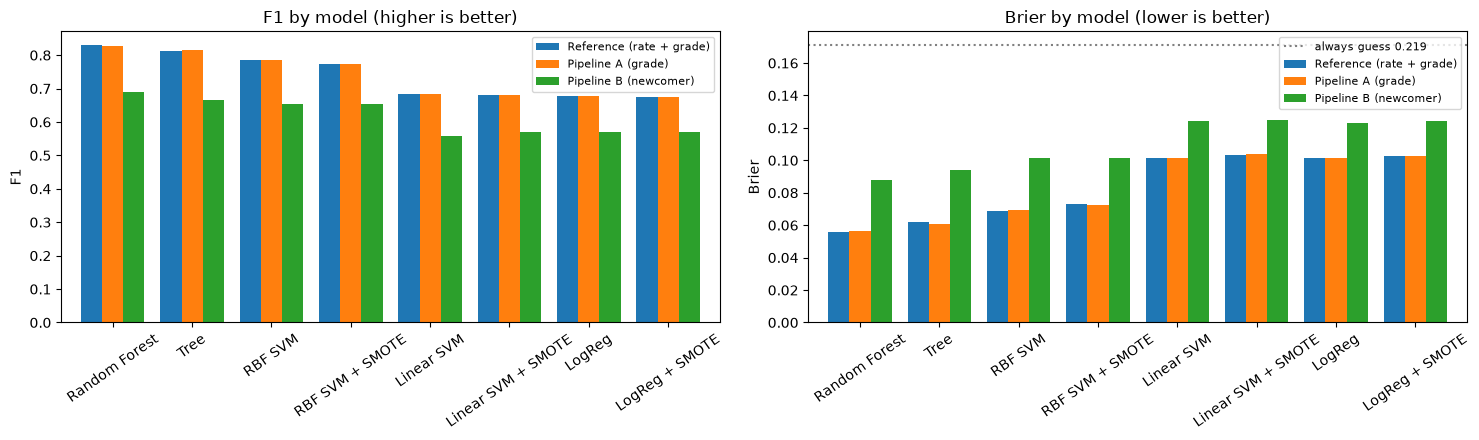

In [3]:
ORDER = ["Random Forest", "Tree", "RBF SVM", "RBF SVM + SMOTE", "Linear SVM", "Linear SVM + SMOTE",
         "LogReg", "LogReg + SMOTE"]
COLS = [s for s, _, _ in SETTINGS]
for metric in ["F1", "ROC-AUC", "Brier"]:
    wide = clf.pivot(index="model", columns="setting", values=metric).reindex(ORDER)[COLS]
    print(f"\n{metric} by model and setting ({'lower' if metric == 'Brier' else 'higher'} is better)")
    display(wide.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metric in zip(axes, ["F1", "Brier"]):
    wide = clf.pivot(index="model", columns="setting", values=metric).reindex(ORDER)[COLS]
    wide.plot.bar(ax=ax, width=0.8)
    ax.set_title(f"{metric} by model ({'lower' if metric == 'Brier' else 'higher'} is better)")
    ax.set_xlabel(""); ax.set_ylabel(metric); ax.tick_params(axis="x", rotation=35)
    if metric == "Brier":
        ax.axhline(0.171, color="grey", linestyle=":", label="always guess 0.219")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Predicting the interest rate: every model and input set

Pipeline A (grade known, notebook 09) and Pipeline B (newcomer, notebook 07). The reference setting has no rate model because its rate is already known.


Pipeline A (grade)  (sorted by RMSE)


RMSE  RMSE sd     MAE  \
inputs               model                                                  
grade + details      Random Forest regressor      0.9968   0.0143  0.7833   
                     Gradient boosting regressor  0.9980   0.0131  0.7835   
grade + details + PD Gradient boosting regressor  0.9980   0.0125  0.7836   
                     Random Forest regressor      0.9989   0.0141  0.7861   
grade + details      Ridge                        1.0075   0.0134  0.7915   
                     Lasso                        1.0075   0.0134  0.7913   
                     Linear regression            1.0075   0.0134  0.7915   
grade + details + PD Lasso                        1.0075   0.0134  0.7914   
                     Ridge                        1.0076   0.0134  0.7916   
                     Linear regression            1.0076   0.0134  0.7916   
grade only           Linear regression            1.0092   0.0134  0.7918   
                     Random Forest regressor      1.0092   0.0134  0.7918   
                     Lasso                        1.0092   0.0134  0.7916   
                     Ridge                        1.0092   0.0134  0.7918   
                     Gradient boosting regressor  1.0093   0.0134  0.7914   
grade + details + PD Mean rate (no model)         3.2415   0.0148  2.6941   

                                                      R2  
inputs               model                                
grade + details      Random Forest regressor      0.9054  
                     Gradient boosting regressor  0.9052  
grade + details + PD Gradient boosting regressor  0.9051  
                     Random Forest regressor      0.9050  
grade + details      Ridge                        0.9033  
                     Lasso                        0.9033  
                     Linear regression            0.9033  
grade + details + PD Lasso                        0.9033  
                     Ridge                        0.9033  
                     Linear regression            0.9033  
grade only           Linear regression            0.9030  
                     Random Forest regressor      0.9030  
                     Lasso                        0.9030  
                     Ridge                        0.9030  
                     Gradient boosting regressor  0.9030  
grade + details + PD Mean rate (no model)        -0.0002


Pipeline B (newcomer)  (sorted by RMSE)


RMSE  RMSE sd  \
inputs                         model                                          
PD + details                   Random Forest regressor      2.7022   0.0318   
PD + details + predicted grade Random Forest regressor      2.7054   0.0309   
PD + details                   Gradient boosting regressor  2.7062   0.0323   
PD + details + predicted grade Linear regression            2.7087   0.0322   
                               Gradient boosting regressor  2.7095   0.0302   
details only (no PD)           Random Forest regressor      2.7114   0.0316   
                               Gradient boosting regressor  2.7134   0.0308   
PD + details                   Linear regression            2.7355   0.0331   
                               Lasso                        2.7355   0.0328   
                               Ridge                        2.7355   0.0330   
details only (no PD)           Linear regression            2.7429   0.0303   
                               Ridge                        2.7429   0.0302   
                               Lasso                        2.7430   0.0300   
PD only                        Gradient boosting regressor  3.0880   0.0266   
                               Random Forest regressor      3.0976   0.0258   
                               Ridge                        3.1666   0.0254   
                               Linear regression            3.1666   0.0254   
                               Lasso                        3.1666   0.0253   
PD + details                   Mean rate (no model)         3.2415   0.0148   

                                                               MAE      R2  
inputs                         model                                        
PD + details                   Random Forest regressor      2.1672  0.3049  
PD + details + predicted grade Random Forest regressor      2.1699  0.3032  
PD + details                   Gradient boosting regressor  2.1700  0.3028  
PD + details + predicted grade Linear regression            2.1712  0.3016  
                               Gradient boosting regressor  2.1719  0.3012  
details only (no PD)           Random Forest regressor      2.1721  0.3002  
                               Gradient boosting regressor  2.1742  0.2991  
PD + details                   Linear regression            2.1982  0.2877  
                               Lasso                        2.1980  0.2877  
                               Ridge                        2.1981  0.2877  
details only (no PD)           Linear regression            2.2009  0.2838  
                               Ridge                        2.2008  0.2838  
                               Lasso                        2.2009  0.2838  
PD only                        Gradient boosting regressor  2.5488  0.0923  
                               Random Forest regressor      2.5544  0.0867  
                               Ridge                        2.6338  0.0455  
                               Linear regression            2.6337  0.0455  
                               Lasso                        2.6338  0.0455  
PD + details                   Mean rate (no model)         2.6941 -0.0002


R² of each rate model (its best input set), Pipeline A vs B:


setting,Pipeline A (grade),Pipeline B (newcomer)
model,,
Linear regression,0.9033,0.3016
Ridge,0.9033,0.2877
Lasso,0.9033,0.2877
Random Forest regressor,0.9054,0.3049
Gradient boosting regressor,0.9052,0.3028


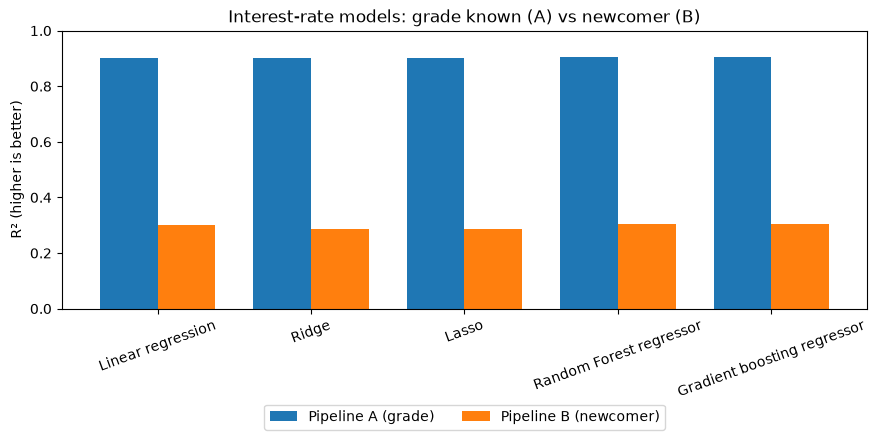

In [4]:
rate_files = {"Pipeline A (grade)": "rate_model_with_grade_validation.csv",
              "Pipeline B (newcomer)": "rate_model_validation.csv"}
rate = []
for setting, f in rate_files.items():
    r = pd.read_csv(REPORTS / f, index_col=[0, 1]).reset_index()
    r = r[~r["inputs"].str.startswith("NO grade")]           # comparison row repeated in notebook 09
    r.insert(0, "setting", setting)
    rate.append(r)
rate = pd.concat(rate, ignore_index=True)
rate["model"] = rate["model"].str.replace(r" \(alpha=.*\)", "", regex=True)
rate.to_csv(REPORTS / "all_rate_scores.csv", index=False)

for setting, g in rate.groupby("setting", sort=False):
    print(f"\n{setting}  (sorted by RMSE)")
    display(g.set_index(["inputs", "model"])[["RMSE", "RMSE sd", "MAE", "R2"]].sort_values("RMSE").round(4))

# Best input set per model, A vs B
best = rate[rate["model"] != "Mean rate (no model)"].sort_values("RMSE").groupby(["setting", "model"]).first().reset_index()
RATE_ORDER = ["Linear regression", "Ridge", "Lasso", "Random Forest regressor", "Gradient boosting regressor"]
wide = best.pivot(index="model", columns="setting", values="R2").reindex(RATE_ORDER)
print("\nR² of each rate model (its best input set), Pipeline A vs B:")
display(wide.round(4))
ax = wide.plot.bar(figsize=(9, 4.8), width=0.75)
ax.set_ylabel("R² (higher is better)"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
ax.set_ylim(0, 1); ax.set_title("Interest-rate models: grade known (A) vs newcomer (B)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
plt.tight_layout(); plt.show()

## 4. Headline: the chosen models per setting

For each setting, the PD model chosen by validation (best tree-based model by Brier score, at its tuned PD cutoff) and the rate model chosen by validation (lowest RMSE). These are the models that will be evaluated once on the test set.

In [5]:
ref_rf = clf[(clf["setting"] == COLS[0]) & (clf["model"] == "Random Forest")].iloc[0]
pdA = json.loads((REPORTS / "graded_pd_choice.json").read_text())
pdB = json.loads((REPORTS / "applicant_pd_choice.json").read_text())
rA = json.loads((REPORTS / "rate_model_with_grade_choice.json").read_text())
rB = json.loads((REPORTS / "rate_model_choice.json").read_text())

def pd_row(setting):
    return clf[(clf["setting"] == setting) & (clf["model"] == "Random Forest")].iloc[0]

head = pd.DataFrame({
    COLS[0]: {"known when deciding": "rate + grade", "PD model": "Random Forest", "PD cutoff": "n/a (reference)",
              "PD F1": ref_rf["F1"], "PD precision": ref_rf["precision"], "PD recall": ref_rf["recall"],
              "PD ROC-AUC": ref_rf["ROC-AUC"], "PD Brier": ref_rf["Brier"],
              "rate model": "none (rate known)", "rate inputs": "-", "rate RMSE (pp)": np.nan, "rate R²": np.nan},
    COLS[1]: {"known when deciding": "grade", "PD model": pdA["model"], "PD cutoff": round(pdA["pd_cutoff"], 3),
              "PD F1": pdA["cv_f1_at_cutoff"], "PD precision": pdA["cv_precision_at_cutoff"],
              "PD recall": pdA["cv_recall_at_cutoff"], "PD ROC-AUC": pd_row(COLS[1])["ROC-AUC"], "PD Brier": pdA["brier"],
              "rate model": rA["model"], "rate inputs": rA["inputs"], "rate RMSE (pp)": rA["cv_rmse"], "rate R²": rA["cv_r2"]},
    COLS[2]: {"known when deciding": "nothing (newcomer)", "PD model": pdB["model"], "PD cutoff": round(pdB["pd_cutoff"], 3),
              "PD F1": pdB["cv_f1_at_cutoff"], "PD precision": pdB["cv_precision_at_cutoff"],
              "PD recall": pdB["cv_recall_at_cutoff"], "PD ROC-AUC": pd_row(COLS[2])["ROC-AUC"], "PD Brier": pdB["brier"],
              "rate model": rB["model"], "rate inputs": rB["inputs"], "rate RMSE (pp)": rB["cv_rmse"], "rate R²": rB["cv_r2"]},
})
display(head.map(lambda v: round(v, 4) if isinstance(v, float) else v))
head.to_csv(REPORTS / "headline_validation.csv")
print("saved reports/headline_validation.csv")

,Reference (rate + grade),Pipeline A (grade),Pipeline B (newcomer)
known when deciding,rate + grade,grade,nothing (newcomer)
PD model,Random Forest,Random Forest,Random Forest
PD cutoff,n/a (reference),0.367,0.388
PD F1,0.8298,0.8269,0.6908
PD precision,0.9553,0.951,0.8204
PD recall,0.7335,0.7316,0.5968
PD ROC-AUC,0.9342,0.9336,0.8824
PD Brier,0.0556,0.0564,0.0879
rate model,none (rate known),Random Forest regressor,Random Forest regressor
rate inputs,-,grade + details,PD + details


saved reports/headline_validation.csv


## 5. What the validation results show

1. **Random Forest is the best default model in every setting**, followed by the single tree, the RBF SVM and then the linear models (logistic regression, linear SVM). The ranking does not change between settings.
2. **SMOTE never improves F1** once the cutoff is tuned; it only trades precision for recall.
3. **The grade carries almost all of the lender's information.** Knowing only the grade (Pipeline A) predicts default as well as knowing both rate and grade (F1 ≈ 0.83, Brier ≈ 0.056). Without it (Pipeline B), F1 falls to ≈ 0.69 and Brier rises to ≈ 0.088.
4. **Every calibrated PD is well calibrated** (mean PD ≈ 0.219, ECE < 0.01). The newcomer pipeline's weaker Brier score comes from weaker separation of risky and safe applicants, not from biased probabilities.
5. **Interest rates follow the grade.** With the grade, R² ≈ 0.905 (grade alone ≈ 0.903). Without it, every method, including gradient boosting and a two-stage model that first predicts the grade, plateaus at R² ≈ 0.30: the limit is the information available, not the model.